<a href="https://colab.research.google.com/github/AnaDiazJ/egci463/blob/main/Pattern_Midterm_Group9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [29]:
# 1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV

summary = {}   # stores the CV / test accuracy of each setting

# 1. Load the dataset
# Subset of Fashion-MNIST: 10,000 images (10 classes x 1,000 images each).

df = pd.read_csv('/content/fashion-mnist-10000.csv')
print("File loaded successfully. Total rows:", len(df))

# 2. Separate labels and features
y = df['label'].astype("uint8")

# 3. Convert the pixel columns to a NumPy array and reshape to 28 x 28 images
X_values = df.drop(columns=['label']).values
assert X_values.shape[1] == 784, "Expected 784 pixel columns (28 x 28)"
X = X_values.reshape(-1, 28, 28)

print("Shapes of X and y:", X.shape, y.shape)  # Expected: (10000, 28, 28) (10000,)

# 4. Split into training and test sets (80% / 20%)
# stratify=y keeps the same class proportions in both sets.
# The test set is only used for the final evaluation.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

File loaded successfully. Total rows: 10000
Shapes of X and y: (10000, 28, 28) (10000,)


In [30]:
# 2
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(8000, 28, 28) (8000,)
(2000, 28, 28) (2000,)


6


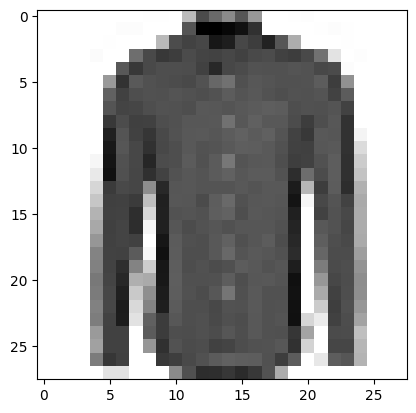

In [31]:
# 3
import matplotlib.pyplot as plt
import numpy as np
print(y[0])
plt.imshow(np.reshape(X[0],[28,28]),cmap='binary')
plt.show()

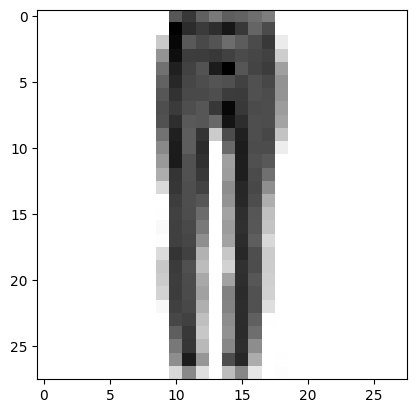

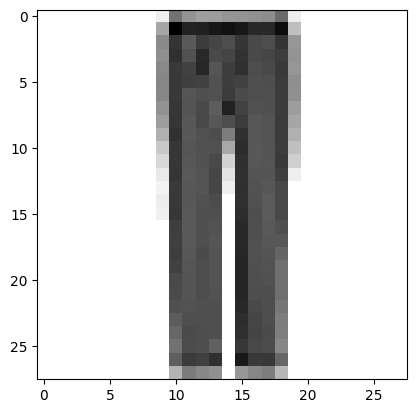

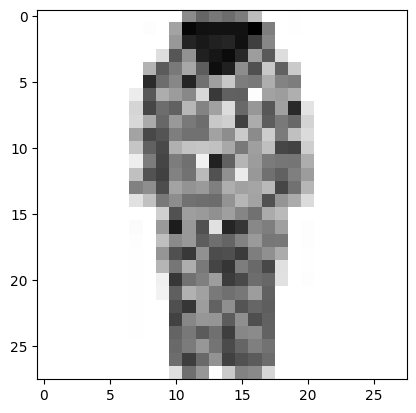

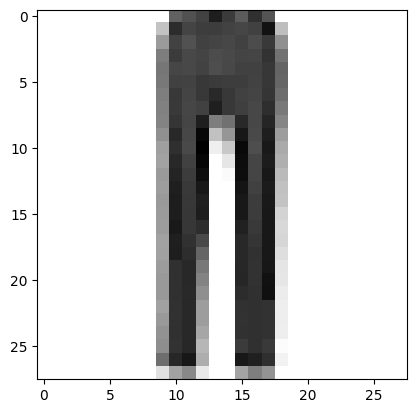

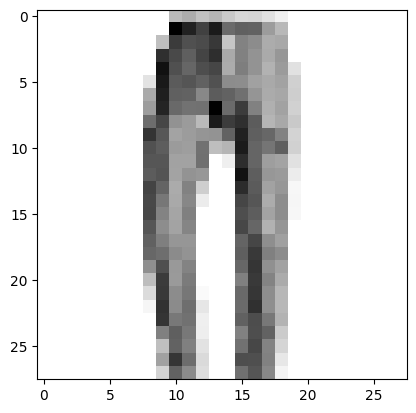

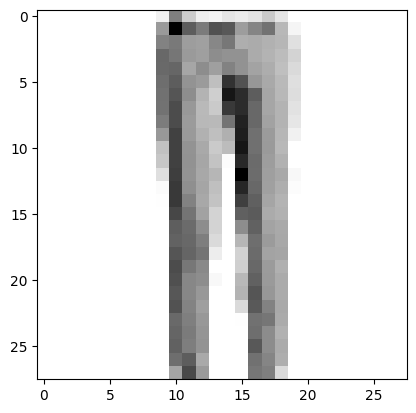

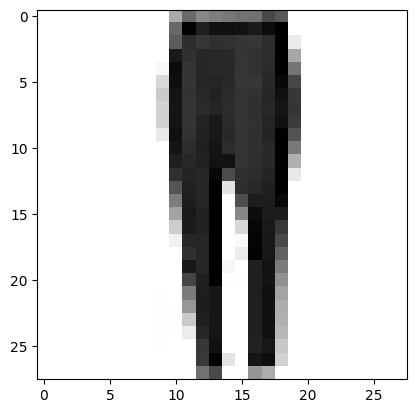

In [32]:
# 4
for elm in range(0,100):
  if y[elm] == 1:
    plt.imshow(np.reshape(X[elm],[28,28]),cmap='binary')
    plt.show()

label
0    1000
1    1000
2    1000
3    1000
4    1000
5    1000
6    1000
7    1000
8    1000
9    1000
Name: count, dtype: int64


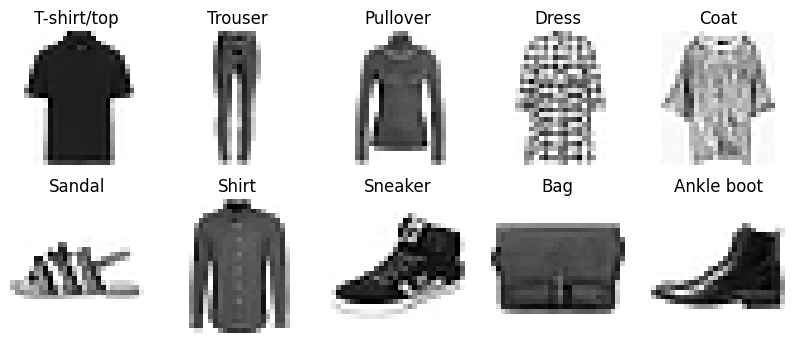

In [33]:
# 5
labels = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
          'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Number of images per class
print(y.value_counts().sort_index())

# Show one example image per class
plt.figure(figsize=(10, 4))
for c in range(10):
    plt.subplot(2, 5, c + 1)
    plt.imshow(X[y == c][0], cmap='binary')
    plt.title(labels[c])
    plt.axis('off')
plt.show()

#Pre-Setting: no scaling

In [34]:
# 6
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Flatten each 28x28 image into a vector of 784 pixels
X_train = X_train.reshape(len(X_train), -1)
X_test  = X_test.reshape(len(X_test), -1)

# Pre-Setting without scaling
# PCA keeps enough components to explain 97% of the variance
# Logistic Regression classifies the 10 classes
pipe = make_pipeline(PCA(0.97, random_state=42),
                     LogisticRegression(max_iter=2000))

# Fit on the training data only (the test set is not used here)
pipe.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Pipeline(steps=[('pca', PCA(n_components=0.97, random_state=42)),
                ('logisticregression', LogisticRegression(max_iter=2000))])

In [35]:
summary["Pre-Setting: no scaling + PCA 97% + LogReg"] = {
    "CV acc": None,    # no cross-validation in this setting
    "Test acc": pipe.score(X_test, y_test),
    "Best params": "PCA 0.97, max_iter=2000, no scaling"
}

In [36]:
# 7
print("Train acc:", pipe.score(X_train, y_train))
print("Test acc:", pipe.score(X_test, y_test))

Train acc: 0.9165
Test acc: 0.8


##The First Setting: StandardScaler, PCA 0.97 variance (332 components), LogisticRegression

In [37]:
# 8
# Setting with scaling
# StandardScaler gives each pixel mean 0 and standard deviation 1
# PCA keeps enough components to explain 97% of the variance
# Logistic Regression classifies the 10 classes
pipe = make_pipeline(
    StandardScaler(),
    PCA(0.97, random_state=42),
    LogisticRegression(max_iter=2000)
)

# Fit on the training data only, the scaler and PCA also learn only from it
pipe.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('pca', PCA(n_components=0.97, random_state=42)),
                ('logisticregression', LogisticRegression(max_iter=2000))])

In [38]:
summary["Setting 1a: scaling + PCA 97% + LogReg (no CV)"] = {
    "CV acc": None,    # no cross-validation in this setting
    "Test acc": pipe.score(X_test, y_test),
    "Best params": "StandardScaler, PCA 0.97, max_iter=2000"
}

In [39]:
# 9
print("Train acc:", pipe.score(X_train, y_train))
print("Test acc:", pipe.score(X_test, y_test))

Train acc: 0.922375
Test acc: 0.818


With StandardScaler the test accuracy improves from 0.8 to 0.818. This is prrobably because scaling gives all pixels the same weight before PCA. This comparison uses only one split, so we check it again with cross-validation below.

####Add cross-validation fold = 5

In [40]:
# 10
# Same pipeline as before, but now evaluated with cross-validation
pipe = Pipeline([
    ('scale', StandardScaler()),                      # scale each pixel
    ('pca', PCA(random_state=42)),                    # reduce dimensions
    ('clf', LogisticRegression(max_iter=2000))        # classifier
])

# Parameters to test, only one value to keep 97% of the variance
param = {'pca__n_components': [0.97]}

# 5-fold cross-validation on the training set => n_jobs=-1 uses all CPU cores
grid = GridSearchCV(pipe, param, cv=5, n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV acc:", grid.best_score_)            # mean accuracy over the 5 folds
print("Test acc   :", grid.score(X_test, y_test))  # accuracy on the held-out test set

# Save the results to build the final comparison table
summary["Setting 1: scaling + PCA 97% + LogReg"] = {
    "CV acc": grid.best_score_,
    "Test acc": grid.score(X_test, y_test),
    "Best params": str(grid.best_params_)
}

Best params: {'pca__n_components': 0.97}
Best CV acc: 0.8125
Test acc   : 0.818


The test accuracy with GridSearchCV is the same as before, because it is the same pipeline (same scaler, PCA and classifier). Cross-validation does not change the model, it only gives a more reliable estimate: the mean CV accuracy (0.8125) is close to the test accuracy (0.818), so the result does not depend on one lucky split.

In [41]:
# 11
print("Components chosen:", grid.best_estimator_.named_steps['pca'].n_components_)

Components chosen: 332


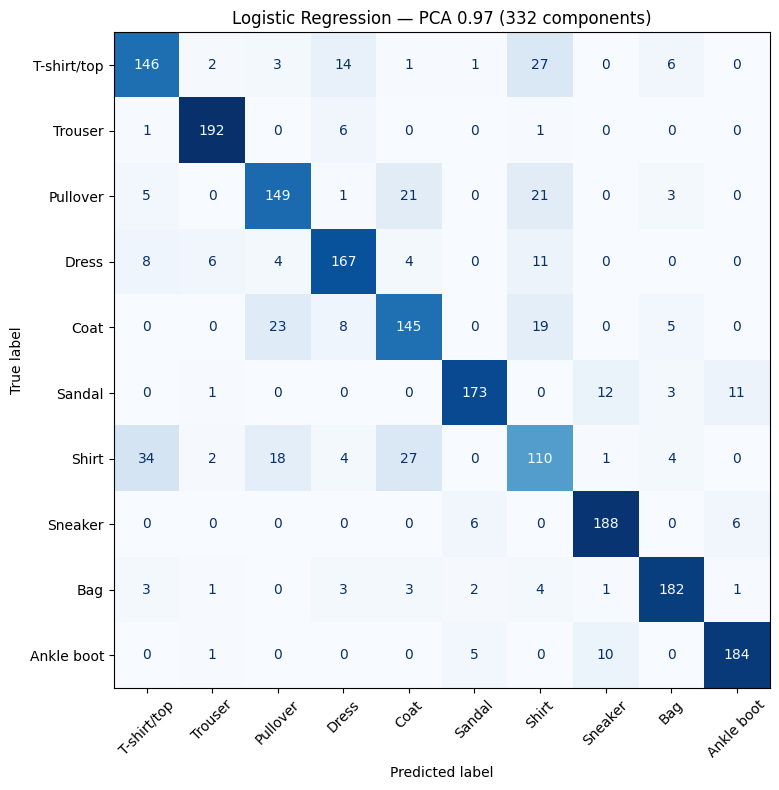

In [42]:
# 12
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Define human-readable class labels for the Fashion-MNIST dataset
labels = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
          'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Generate predictions on the test set using the tuned grid search model
y_pred = grid.predict(X_test)

# Compute the confusion matrix comparing true labels vs. predicted labels
cm = confusion_matrix(y_test, y_pred)

# Initialize the ConfusionMatrixDisplay object with the matrix and custom labels
disp = ConfusionMatrixDisplay(cm, display_labels=labels)

# Create a square figure (8x8 inches) to ensure the 10x10 grid is readable
fig, ax = plt.subplots(figsize=(8, 8))

# Plot the confusion matrix with styling options:
#    - cmap='Blues': Use a blue color gradient (darker = higher values)
#    - colorbar=False: Omit the side color scale for a cleaner look
#    - xticks_rotation=45: Tilt x-axis labels by 45 degrees to prevent overlapping
#    - ax=ax: Render on the specified matplotlib axis
disp.plot(cmap='Blues', colorbar=False, xticks_rotation=45, ax=ax)

# Add a descriptive title indicating model details and PCA components
plt.title("Logistic Regression — PCA 0.97 (332 components)")

# Adjust plot parameters to ensure all labels and titles fit neatly without clipping
plt.tight_layout()

# 9. Render and display the final plot
plt.show()

#The Second Setting: LogisticRegression, with and without scaling, different PCA components

In [43]:
# 13
#Logistic Regression, but we now compare several options
pipe = Pipeline([
    ('scale', StandardScaler()),                  #scaling step, will try it on and off
    ('pca', PCA(random_state=42)),                #reduce dimensions
    ('clf', LogisticRegression(max_iter=2000))    #classifier
])

# 2 scaling choices x 5 numbers of components = 10 combinations
param = {
    'scale': [StandardScaler(), 'passthrough'],   #with scaling / without scaling
    'pca__n_components': [20, 50, 100, 150, 200]
}

# 5-fold cross-validation on the training set for every combination
grid = GridSearchCV(pipe, param, cv=5, n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)            # best combination found
print("Best CV acc:", grid.best_score_)             # mean accuracy over the 5 folds
print("Test acc   :", grid.score(X_test, y_test))   # accuracy on the held-out test set

# Keep the best choices (not used later, only for reference)
best_n = grid.best_params_['pca__n_components']
best_scale = grid.best_params_['scale']

# Save the results to build the final comparison table
summary["Setting 2: LogReg, best of scaling x n_components"] = {
    "CV acc": grid.best_score_,
    "Test acc": grid.score(X_test, y_test),
    "Best params": str(grid.best_params_)
}

Best params: {'pca__n_components': 50, 'scale': 'passthrough'}
Best CV acc: 0.8261249999999999
Test acc   : 0.8175


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [44]:
# 14
import pandas as pd

results = pd.DataFrame(grid.cv_results_)
cols = ['param_scale', 'param_pca__n_components', 'mean_test_score', 'std_test_score', 'rank_test_score']
display(results[cols].sort_values('rank_test_score'))

,param_scale,param_pca__n_components,mean_test_score,std_test_score,rank_test_score
3,passthrough,50,0.826125,0.006724,1
4,StandardScaler(),100,0.823875,0.009523,2
6,StandardScaler(),150,0.823250,0.009869,3
2,StandardScaler(),50,0.821625,0.008818,4
8,StandardScaler(),200,0.818500,0.008155,5
5,passthrough,100,0.818375,0.010596,6
1,passthrough,20,0.803500,0.009317,7
7,passthrough,150,0.801625,0.007022,8
0,StandardScaler(),20,0.793875,0.005908,9
9,passthrough,200,0.782625,0.013261,10


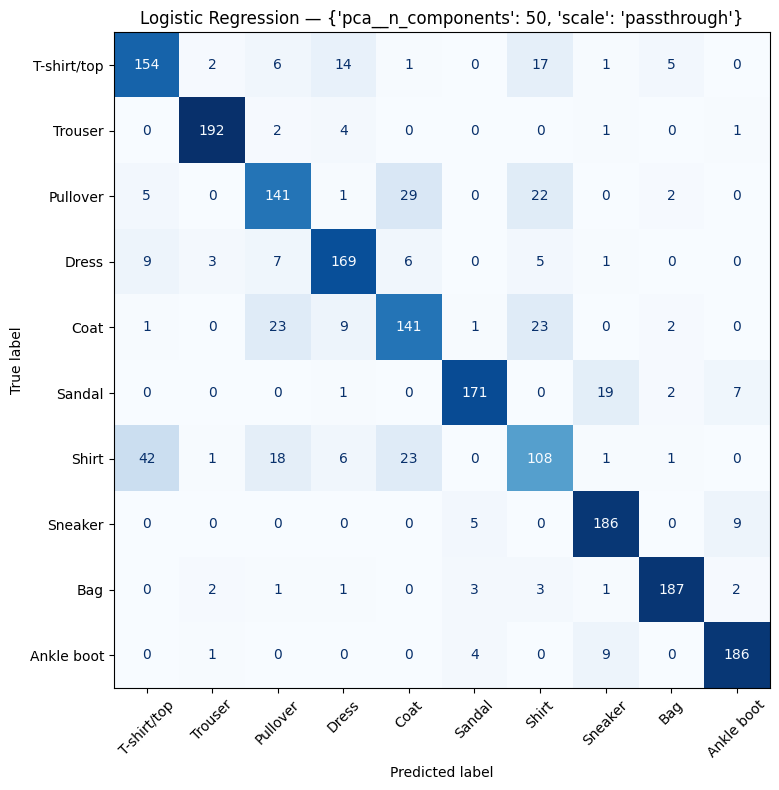

In [45]:
# 15
y_pred = grid.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(cm, display_labels=labels)
fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(cmap='Blues', colorbar=False, xticks_rotation=45, ax=ax)
plt.title(f"Logistic Regression — {grid.best_params_}")
plt.tight_layout()
plt.show()

#The Third Setting: Perceptron, with and without scaling, PCA with 50 or 100 components

In [46]:
# 16
from sklearn.linear_model import Perceptron
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Construct a machine learning pipeline for sequential data preprocessing and modeling
pipeline = Pipeline([
    ('scaler', StandardScaler()),                        # Standardize features (mean=0, variance=1)
    ('pca', PCA(random_state=42)),                       # Dimensionality reduction using PCA
    ('clf', Perceptron(max_iter=2000, random_state=42))  # Perceptron classifier with up to 2000 epochs
])

In [47]:
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler

# Hyperparameter grid to tune the pipeline with the Perceptron
param_grid = {
    'scaler': [StandardScaler(), 'passthrough'],     # Scaling the data vs leaving it unscaled
    'pca__n_components': [50, 100],                  # Keep either 50 or 100 components
    'clf__eta0': [0.0001, 0.001, 0.01],              # Use different learning rates
    'clf__penalty': [None, 'l2', 'elasticnet'],      # Use different regularization penalties to not fall on overfitting
}

#Begin GridSearchCV with 5-fold cross-validation using all available CPU cores (n_jobs=-1)
grid = GridSearchCV(pipeline, param_grid, cv=5, n_jobs=-1)

#Fit the grid search to the training data to find the optimal combination of hyperparameters
grid.fit(X_train, y_train)

# Print best-performing hyperparameters and the resulting accuracies
print("Best params:", grid.best_params_)
print("Best CV acc:", grid.best_score_)
print("Test acc   :", grid.score(X_test, y_test))

# Get and save the best-performing pipeline model instance
best = grid.best_estimator_

#Store the metrics of the Perceptron model in the summary
summary["Setting 3: Perceptron"] = {
    "CV acc": grid.best_score_,
    "Test acc": grid.score(X_test, y_test),
    "Best params": str(grid.best_params_)
}

Best params: {'clf__eta0': 0.01, 'clf__penalty': None, 'pca__n_components': 100, 'scaler': StandardScaler()}
Best CV acc: 0.7701250000000001
Test acc   : 0.759


In [48]:
# 18
import pandas as pd

results = pd.DataFrame(grid.cv_results_)
cols = ['param_scaler', 'param_pca__n_components', 'param_clf__eta0', 'param_clf__penalty',
        'mean_test_score', 'std_test_score', 'rank_test_score']
display(results[cols].sort_values('rank_test_score').head(36))

,param_scaler,param_pca__n_components,param_clf__eta0,param_clf__penalty,mean_test_score,std_test_score,rank_test_score
26,StandardScaler(),100,0.0100,None,0.770125,0.020734,1
30,StandardScaler(),100,0.0100,l2,0.764375,0.012061,2
34,StandardScaler(),100,0.0100,elasticnet,0.761000,0.014920,3
22,StandardScaler(),100,0.0010,elasticnet,0.755875,0.013889,4
14,StandardScaler(),100,0.0010,None,0.754750,0.016633,5
10,StandardScaler(),100,0.0001,elasticnet,0.749000,0.019238,6
18,StandardScaler(),100,0.0010,l2,0.744375,0.020589,7
8,StandardScaler(),50,0.0001,elasticnet,0.743375,0.013054,8
2,StandardScaler(),100,0.0001,None,0.742125,0.032391,9
6,StandardScaler(),100,0.0001,l2,0.741750,0.033118,10


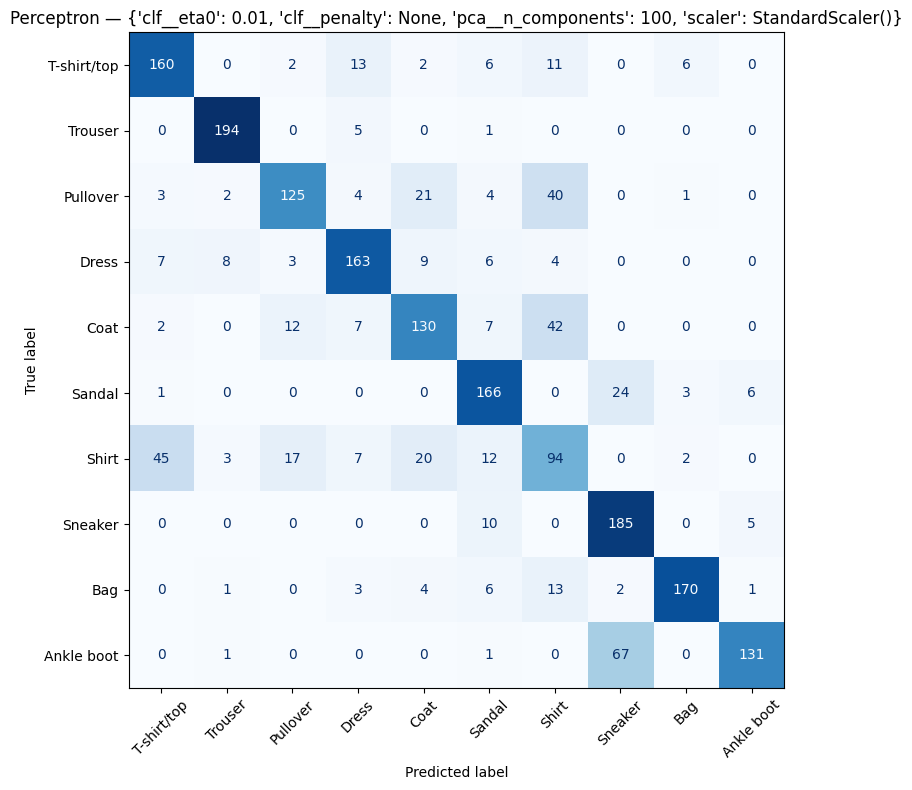

In [49]:
# 19
y_pred = grid.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(cm, display_labels=labels)
fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(cmap='Blues', colorbar=False, xticks_rotation=45, ax=ax)
plt.title(f"Perceptron — {grid.best_params_}")
plt.tight_layout()
plt.show()

In [50]:
pd.set_option('display.max_colwidth', None)
comparison = pd.DataFrame(summary).T.sort_values("CV acc", ascending=False)
display(comparison)

,CV acc,Test acc,Best params
"Setting 2: LogReg, best of scaling x n_components",0.826125,0.8175,"{'pca__n_components': 50, 'scale': 'passthrough'}"
Setting 1: scaling + PCA 97% + LogReg,0.8125,0.818,{'pca__n_components': 0.97}
Setting 3: Perceptron,0.770125,0.759,"{'clf__eta0': 0.01, 'clf__penalty': None, 'pca__n_components': 100, 'scaler': StandardScaler()}"
Pre-Setting: no scaling + PCA 97% + LogReg,None,0.8,"PCA 0.97, max_iter=2000, no scaling"
Setting 1a: scaling + PCA 97% + LogReg (no CV),None,0.818,"StandardScaler, PCA 0.97, max_iter=2000"


### Setting 1 vs Setting 2
Setting 1 uses StandardScaler + PCA keeping 97% of the variance (332 components). Setting 2 searched scaling vs. no scaling and 20-200 components. The best Setting 2 uses no scaling and 50 components (CV 0.826 vs 0.813 for Setting 1), but it is only slightly better than the best scaled model (100 components, CV 0.824), and the difference is smaller than the CV standard deviation (about 0.01). The test accuracies are almost the same (0.818 vs 0.8175). Scaling helped when many components were used (CV 0.823 vs 0.802 at 150 components, and 0.819 vs 0.783 at 200), and it also helped in the first comparison with 97% variance (test 0.8 vs 0.818). With few components (20-50) no scaling was slightly better. More than 100 components did not improve the results, probably because the extra components mostly add noise.

### Setting 2 vs Setting 3
Setting 3 changes the classifier (Logistic Regression vs Perceptron). The Perceptron obtained CV 0.770 and test 0.759, which is lower than Logistic Regression (CV 0.826, test 0.8175). The Perceptron is a simpler linear model: it only updates when it makes a mistake and has no probabilities, so it is less stable when classes overlap.
Scaling was important for the Perceptron (CV 0.770 with scaling vs about 0.685 without), and it also helped Logistic Regression when many components were used.

### Confused classes
In the confusion matrices the most confused classes are Shirt, T-shirt/top, Pullover and Coat. Shirt is the hardest class (it is often predicted as T-shirt/top, Coat or Pullover), and Pullover and Coat are also mixed with each other. These classes have very similar shapes, so a linear model on PCA features cannot separate them well. Classes with clear shapes (Trouser, Bag, Sneaker) are almost always correct. The Perceptron also confuses Ankle boot with Sneaker much more than Logistic Regression does.

### Limitations and next steps
The differences between the two Logistic Regression settings (about 0.1 points in test accuracy) are smaller than the standard deviation of the CV (about 0.01), so we cannot say one is clearly better. Next we would try LDA, a non-linear classifier (SVM with RBF kernel) and better features, such as the ones from a CNN.

#STAGE 2

In Stage 1, we worked with 10,000 Fashion-MNIST images, with 1,000 images for each of the 10 classes. We split the data into 8,000 training images and 2,000 test images, keeping the class proportions. We compared several PCA configurations with logistic regression and perceptron. The selected configuration was PCA with 50 components and logistic regression. It achieved 82.61% accuracy in cross-validation on the training data and 81.75% on the test set.

In Stage 2, we will keep the same training and test images. We will use the 81.75% as a reference result to compare the new methods. We will also check if the classification of Shirt, the class that gave the most trouble in Stage 1, improves.

In [61]:
img = X_train[0].reshape(28, 28).astype(float)   # back to a 28x28 image          # float so the subtraction does not wrap around (uint8)

gx = img[1:-1, 2:] - img[1:-1, :-2]     # horizontal change: right neighbour - left neighbour
gy = img[2:, 1:-1] - img[:-2, 1:-1]     # vertical change: bottom neighbour - top neighbour

mag = np.sqrt(gx**2 + gy**2)            # magnitude: how strong the edge is
ang = np.rad2deg(np.arctan2(gy, gx))    # angle: direction in which the brightness changes

In [62]:
print(mag[0, 0], mag[13, 13])   # background (black) vs. centre of the garment

0.0 4.47213595499958


In [63]:
print(mag.max())                                  # strongest edge in the image
print(np.unravel_index(mag.argmax(), mag.shape))  # where it is (row, col)

340.177894637497
(np.int64(2), np.int64(5))


In [64]:
# Normalize pixel values to the 0-1 range
# (remove "/ 255.0" if your values are already between 0 and 1)
X_train = X_train.astype('float32') / 255.0
X_test  = X_test.astype('float32') / 255.0

In [65]:
#Add a dimension of the canal, Conv2D waits for 4 dimensions
if X_train.ndim == 3:
    X_train = X_train[..., np.newaxis]
    X_test  = X_test[..., np.newaxis]

In [74]:
# Labels are integers -> use the sparse version of the loss
num_classes = len(np.unique(y_train))
loss = 'sparse_categorical_crossentropy'

In [75]:
print("y_train shape:", y_train.shape)
print("Classes detected:", num_classes)
print("Loss function:", loss)
print("Unique labels:", np.unique(y_train))

y_train shape: (8000,)
Classes detected: 10
Loss function: sparse_categorical_crossentropy
Unique labels: [0 1 2 3 4 5 6 7 8 9]


In [77]:
# Reshape flattened vectors (N, 784) back into images (N, 28, 28, 1)
# 28 x 28 = 784, and the last "1" is the single grayscale channel
X_train = X_train.reshape(-1, 28, 28, 1)
X_test  = X_test.reshape(-1, 28, 28, 1)

# Save the input shape for the first layer of the CNN
input_shape = X_train.shape[1:]

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("Input shape:", input_shape)
print("Min/max:", X_train.min(), X_train.max())

X_train: (8000, 28, 28, 1)
X_test:  (2000, 28, 28, 1)
Input shape: (28, 28, 1)
Min/max: 0.0 1.0


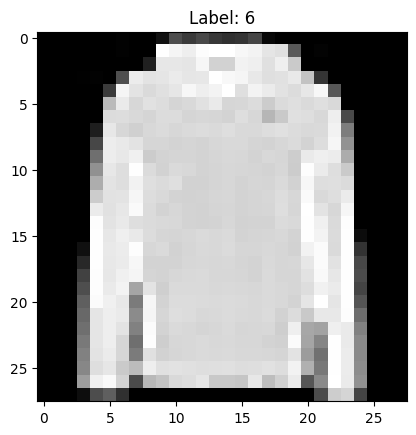

In [78]:
import matplotlib.pyplot as plt

plt.imshow(X_train[0].squeeze(), cmap='gray')
plt.title(f"Label: {y_train[0]}")
plt.show()

In [79]:
from keras.utils import to_categorical

# Convert integer labels (0-9) into one-hot vectors, e.g. 3 -> [0,0,0,1,0,0,0,0,0,0]
y_train_cat = to_categorical(y_train, num_classes=10)
y_test_cat  = to_categorical(y_test,  num_classes=10)

print(y_train_cat.shape)   # (8000, 10)

(8000, 10)


In [80]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D

input_shape = (28, 28, 1)

model = Sequential()
# Two stacked conv layers (no padding, so the image shrinks: 28 -> 26 -> 24)
model.add(Conv2D(64, kernel_size=(3, 3), activation='relu', input_shape=input_shape))
model.add(Conv2D(64, (3, 3), activation='relu'))
# Pooling 3x3 divides the size by 3: 24 -> 8
model.add(MaxPooling2D(pool_size=(3, 3)))
model.add(Dropout(0.25))
# Flatten 8x8x64 = 4096 values and classify with dense layers
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(10, activation='softmax'))

model.compile(loss='categorical_crossentropy', optimizer='Adam', metrics=['accuracy'])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 563,274 (2.15 MB)

 Trainable params: 563,274 (2.15 MB)

 Non-trainable params: 0 (0.00 B)

In [81]:
history = model.fit(
    X_train, y_train_cat,
    epochs=20,
    batch_size=32,
    validation_data=(X_test, y_test_cat)
)

Epoch 1/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 29s 110ms/step - accuracy: 0.6998 - loss: 0.8553 - val_accuracy: 0.8170 - val_loss: 0.4964
Epoch 2/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 34s 82ms/step - accuracy: 0.8000 - loss: 0.5418 - val_accuracy: 0.8530 - val_loss: 0.4111
Epoch 3/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 23s 91ms/step - accuracy: 0.8299 - loss: 0.4668 - val_accuracy: 0.8595 - val_loss: 0.3869
Epoch 4/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 41s 90ms/step - accuracy: 0.8482 - loss: 0.4139 - val_accuracy: 0.8685 - val_loss: 0.3560
Epoch 5/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 20s 82ms/step - accuracy: 0.8595 - loss: 0.3873 - val_accuracy: 0.8835 - val_loss: 0.3382
Epoch 6/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 20s 82ms/step - accuracy: 0.8664 - loss: 0.3566 - val_accuracy: 0.8735 - val_loss: 0.3410
Epoch 7/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 20s 79ms/step - accuracy: 0.8751 - loss: 0.3346 - val_accuracy: 0.8810 - val_loss: 0.3414
Epoch 8/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 21s 81ms/step - accuracy: 0.8817 - loss: 0.3120 -

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step
              precision    recall  f1-score   support

           0       0.81      0.86      0.84       200
           1       0.98      0.98      0.98       200
           2       0.87      0.82      0.85       200
           3       0.88      0.88      0.88       200
           4       0.78      0.91      0.84       200
           5       0.97      0.98      0.98       200
           6       0.80      0.66      0.72       200
           7       0.95      0.96      0.96       200
           8       0.98      0.98      0.98       200
           9       0.97      0.94      0.96       200

    accuracy                           0.90      2000
   macro avg       0.90      0.90      0.90      2000
weighted avg       0.90      0.90      0.90      2000



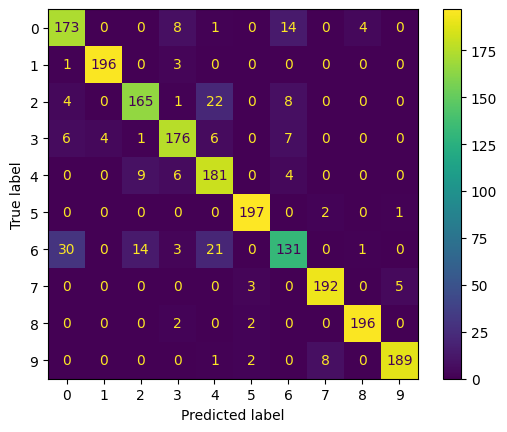

In [82]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Predict probabilities and take the most likely class for each image
y_pred = np.argmax(model.predict(X_test), axis=1)

# Confusion matrix: rows = true class, columns = predicted class
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot()

# Precision, recall and F1 per class
print(classification_report(y_test, y_pred))

In [83]:
import matplotlib.pyplot as plt
from keras.callbacks import ModelCheckpoint

# Save the weights only when validation accuracy improves
cb = [ModelCheckpoint('best_model.weights.h5', monitor='val_accuracy',
                      save_best_only=True, mode='max', verbose=1)]

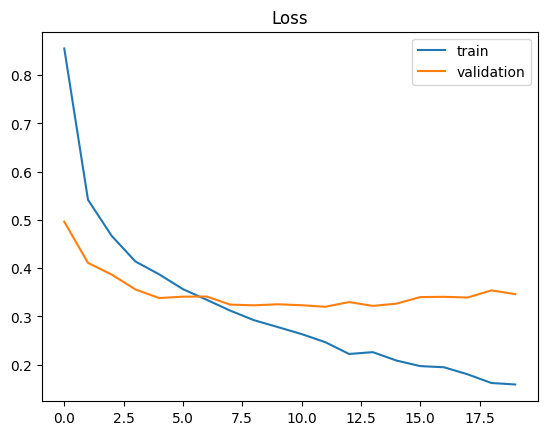

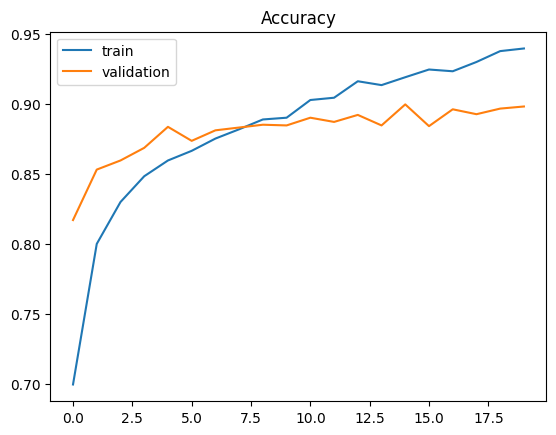

In [84]:
# Compare training and validation curves to detect overfitting
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.legend(); plt.title('Loss'); plt.show()

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='validation')
plt.legend(); plt.title('Accuracy'); plt.show()